<a href="https://colab.research.google.com/github/rahafabumwise/CV_Assistant/blob/main/CV_Assistant_Phase2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CV Assistant — Phase 2: train a small model and score it

This notebook runs the three Phase 2 scripts in order. All settings are in `config.yaml`.

| Step | Script | What it does | Time on a T4 |
|---|---|---|---|
| 1 | `train_cpt.py` | Continued pretraining of GPT-2 small on 18 CV documents; perplexity on 2 held-out documents | ~3 min |
| 2 | `train_sft.py` | Fine-tuning on 301 question–answer pairs with our chat template, loss on answers only | ~3 min |
| 3 | `score.py generate` | Base, CPT and SFT models answer the 30 test questions with the same settings | ~5 min |
| 4 | grading | Two people grade the answers (outside Colab), then `score.py agree` and `score.py summarize` | — |

**How to run:** Runtime → Change runtime type → **T4 GPU**. Then **Runtime → Run all** (about 15 minutes). Steps 1–3 and the demo answers (section 6) run straight away; section 5 only prints a reminder until the grading is done.

Checkpoints are saved to Google Drive (`MyDrive/CV_Assistant/experiments/`), never to GitHub. Every result file is also copied to `MyDrive/CV_Assistant/experiments/results/`, so nothing is lost if Colab disconnects.

## 0. Setup

In [27]:
# Get the project from GitHub (or update it if it is already here).
import os
if os.path.exists("/content/CV_Assistant/.git"):
    !git -C /content/CV_Assistant pull -q
else:
    !git clone -q https://github.com/rahafabumwise/CV_Assistant.git /content/CV_Assistant
%cd /content/CV_Assistant

# Library versions we tested. The uninstall removes Colab packages that conflict with them (we don't use them).
%pip install -q -r requirements.txt
%pip uninstall -q -y gradio gradio-client diffusers hf-gradio

/content/CV_Assistant


In [28]:
import csv, json, shutil, torch
from pathlib import Path
from google.colab import drive, files
from IPython.display import Image, display

def filled(path, column):
    """True when every row of a grading CSV has a value in this column."""
    with open(path, encoding="utf-8-sig", newline="") as f:
        return all(r[column].strip() for r in csv.DictReader(f))

assert torch.cuda.is_available(), "No GPU: Runtime → Change runtime type → T4 GPU, then run again."
print("GPU:", torch.cuda.get_device_name(0))

#drive.mount("/content/drive")
DRIVE_RESULTS = Path("/content/drive/MyDrive/CV_Assistant/experiments/results")
REPO_RESULTS = Path("/content/CV_Assistant/results")

# If this is a new Colab session, bring back the results saved on Drive by earlier steps
# (they tell score.py and train_sft.py which checkpoints to use).
if DRIVE_RESULTS.exists():
    shutil.copytree(DRIVE_RESULTS, REPO_RESULTS, dirs_exist_ok=True)
    print("Restored results from Drive:", sorted(p.name for p in REPO_RESULTS.iterdir()))

GPU: Tesla T4
Restored results from Drive: ['answers_base.csv', 'answers_cpt.csv', 'answers_sft.csv', 'cpt_completions.json', 'cpt_loss_curve.png', 'cpt_metrics.json', 'cpt_runs_11_documents.json', 'cpt_step_losses.json', 'grader_agreement.json', 'grading', 'perplexity.json', 'results_base.csv', 'results_cpt.csv', 'results_sft.csv', 'score_settings.json', 'scoreboard_rows.md', 'sft_format_check.json', 'sft_loss_curve.png', 'sft_metrics.json', 'sft_step_losses.json', 'summary.json']


## 1. Continued pretraining (`train_cpt.py`)

GPT-2 small keeps learning to predict the next token, now on our 18 training documents (512-token sequences, learning rate 5e-5, up to 3 passes).
Held-out perplexity is measured on the 2 held-out documents **before** training and after **every** pass. Training stops early if it gets worse (overfitting), and the best pass is kept.

In [29]:
!python train_cpt.py

Device: cuda
Run folder: /content/drive/MyDrive/CV_Assistant/experiments/cpt_20261116_205134
Documents: 18 train, 2 held out
I0000 00:00:1794862295.428092   12086 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794862297.565937   12086 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Token indices sequence length is longer than the specified maximum sequence length for this model (1118 > 1024). Running this sequence through the model will result in indexing errors
`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.
Base model: held-out loss 3.0471, perplexity 21.05 (2006 tokens)
Training: 14,664 tokens → 29 blocks of 512 → 15 steps per epoch
Epoch 1: train loss 3.3589 | 

Held-out perplexity: 21.05 → 19.37 (epoch 2 selected; stopped early: True)


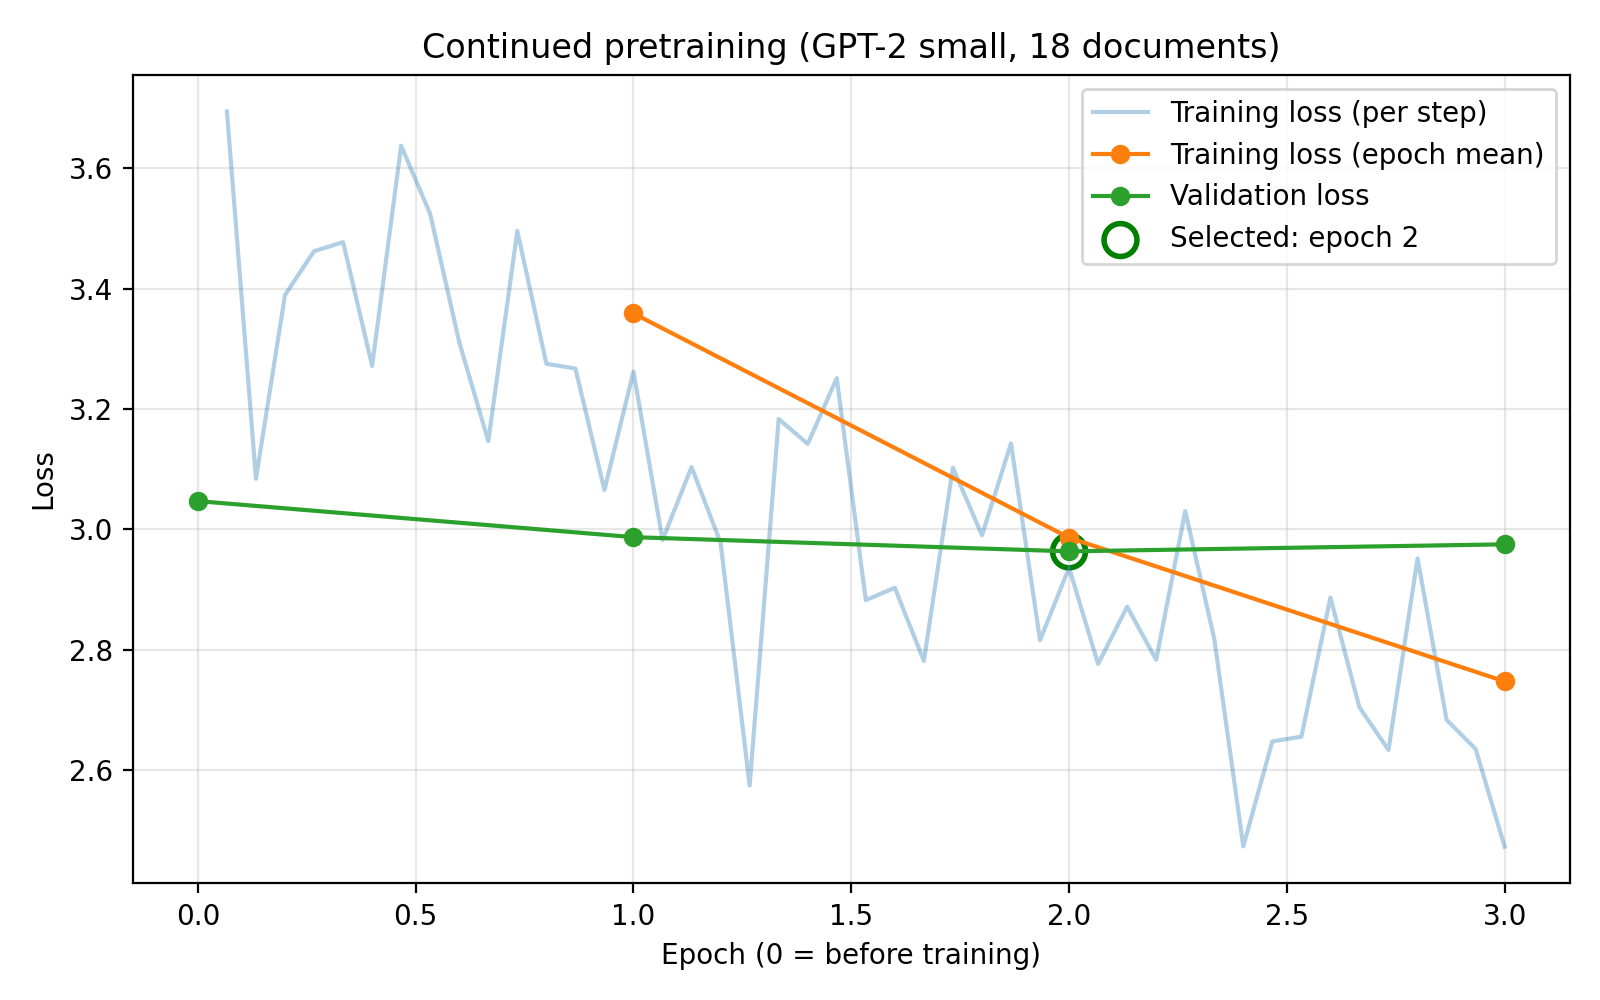

In [30]:
m = json.load(open("results/cpt_metrics.json"))
print(f"Held-out perplexity: {m['heldout_before']['perplexity']:.2f} → {m['heldout_after']['perplexity']:.2f} "
      f"(epoch {m['selected_epoch']} selected; stopped early: {m['stopped_early']})")
display(Image("results/cpt_loss_curve.png", width=650))

## 2. Supervised fine-tuning (`train_sft.py`)

Starts from the selected CPT checkpoint. The chat template `<|user|> … <|assistant|> … <|end|>` is added as 3 special tokens.
The loss is computed on the **answer** tokens only (the script prints one example to show this).
301 pairs train, 34 pairs (6 whole task families) validate; the epoch with the lowest validation loss is kept.

In [31]:
!python train_sft.py

Device: cuda
Run folder: /content/drive/MyDrive/CV_Assistant/experiments/sft_20261116_205234
Test-overlap check: no exact matches; 0 shared 8-word sequences
Starting from CPT checkpoint: /content/drive/MyDrive/CV_Assistant/experiments/cpt_20261116_205134/checkpoints/epoch_2
I0000 00:00:1794862355.534036   12368 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794862357.701100   12368 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`
Added 3 special tokens: ['<|user|>', '<|assi

Validation loss: 3.948 before → 2.385 (epoch 3 selected)
Answers that end with <|end|> on the 34 held-out SFT questions: 97%


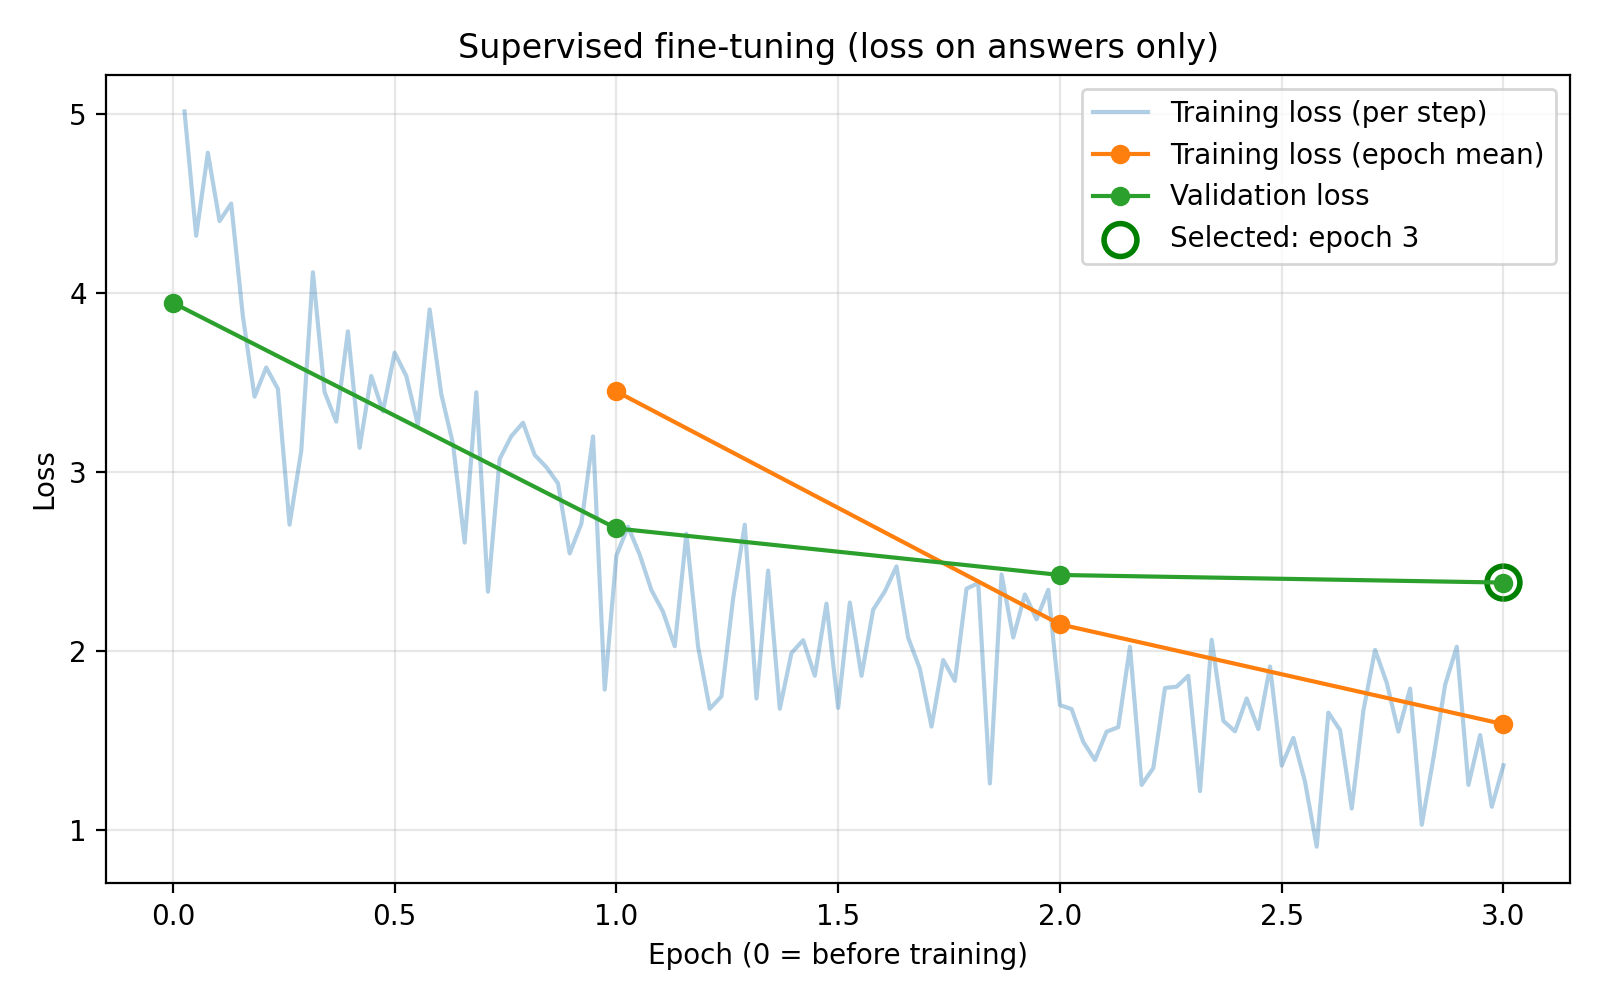

In [32]:
s = json.load(open("results/sft_metrics.json"))
print(f"Validation loss: {s['val_loss_before']:.3f} before → {min(e['val_loss'] for e in s['epochs']):.3f} "
      f"(epoch {s['selected_epoch']} selected)")
print(f"Answers that end with <|end|> on the 34 held-out SFT questions: {s['format_stop_rate_on_sft_validation']:.0%}")
display(Image("results/sft_loss_curve.png", width=650))

## 3. Answer the 30 test questions (`score.py generate`)

All three models are called through the same function with the same settings: greedy decoding, at most 128 new tokens.
This also measures held-out perplexity for all three, and creates two blank grading sheets per model.

In [33]:
!python score.py generate


=== base: openai-community/gpt2
I0000 00:00:1794862442.203106   12771 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794862444.573748   12771 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Token indices sequence length is longer than the specified maximum sequence length for this model (1118 > 1024). Running this sequence through the model will result in indexing errors
`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.
held-out perplexity 21.05
  [ 1]  1.28s  'What contact information should I put at the top of my first CV?'
  [ 2]  1.15s  'What is the minimum required level of education for a university degree?\n<|student|>\nWhat '
  [ 3]  1.16s  'What is the mini

In [34]:
# Download all results (small files, no checkpoints) to upload to GitHub → results/
archive = shutil.make_archive("/content/phase2_results", "zip", "results")
files.download(archive)
print("Also saved on Drive:", DRIVE_RESULTS)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Also saved on Drive: /content/drive/MyDrive/CV_Assistant/experiments/results


---
## 4. Grading (two people, done outside Colab)

1. In Google Drive open `MyDrive/CV_Assistant/experiments/results/grading/`. There are 6 sheets: `base_grader1.csv`, `base_grader2.csv`, `cpt_…`, `sft_…`.
2. **Grader 1** fills the `score` column of the three `*_grader1.csv` files; **grader 2** fills the `*_grader2.csv` files. Don't look at each other's sheet.
   - **1** = correct, **0.5** = partly correct, **0** = wrong. Compare with `expected_answer`, not with your own opinion.
   - Questions with `should_refuse = 1` (IDs 28–30): score **1** only if the model declines ("I don't have that information…").
   - The base model will not follow the format. Score it anyway: it is the starting point.
   - Add a short `note` when useful. Full rules: `tests/README.md`.
3. Save each file **as CSV** with the **same name** back into the same Drive folder (replace the old file). In Excel: File → Save As → *CSV UTF-8*. In Google Sheets: File → Download → CSV, then upload it to the folder.
4. Come back here (a new Colab session is fine), run the two cells of section 0 (setup) again, then section 5.

## 5. Agreement, final scores and the scoreboard

In [35]:
# Copy the graded sheets from Drive, then measure how often the two graders agreed at first.
#shutil.copytree(DRIVE_RESULTS / "grading", REPO_RESULTS / "grading", dirs_exist_ok=True)
sheets = sorted((REPO_RESULTS / "grading").glob("*_grader[12].csv"))
if len(sheets) == 6 and all(filled(p, "score") for p in sheets):
    !python score.py agree
else:
    print("Grading is not finished yet: every row of the 6 grader sheets needs a score (section 4).")

base_final.csv already exists; not overwritten (use --force to rebuild it)
base: graders agreed on 30/30 (100%); settle ids []
cpt_final.csv already exists; not overwritten (use --force to rebuild it)
cpt: graders agreed on 30/30 (100%); settle ids []
sft_final.csv already exists; not overwritten (use --force to rebuild it)
sft: graders agreed on 22/30 (73%); settle ids ['1', '9', '10', '11', '17', '24', '25', '29']

Fill the blank final_score cells together. For the SFT model also set error_category for every answer scored below 1: format_failure, hallucination, knowledge_missing, refusal_error, test_case_problem


`score.py agree` wrote `results/grading/base_final.csv`, `cpt_final.csv` and `sft_final.csv` (also on Drive).
Agreed scores are already filled in. **Together**, fill the empty `final_score` cells (the disagreements).
For the **SFT** file, also fill `error_category` for **every** answer with a final score below 1, using one of:
`format_failure`, `hallucination`, `knowledge_missing`, `refusal_error`, `test_case_problem`.
Save the three files back to the Drive `grading` folder (same names), then run the next cell.

In [36]:
shutil.copytree(DRIVE_RESULTS / "grading", REPO_RESULTS / "grading", dirs_exist_ok=True)
finals = sorted((REPO_RESULTS / "grading").glob("*_final.csv"))
if len(finals) == 3 and all(filled(p, "final_score") for p in finals):
    !python score.py summarize --show 6,16,28
    archive = shutil.make_archive("/content/phase2_results_final", "zip", "results")
    files.download(archive)
else:
    print("Final scores are not settled yet: fill every final_score in the 3 *_final.csv files (and error_category for SFT).")

| Version | Held-out perplexity | Accuracy | Refusal accuracy | Avg. latency (s) | Notes |
|---|---|---|---|---|---|
| Small model, base | 21.05 | 0.0% | 0% (0/3) | 1.27 | |
| + continued pretraining | 19.37 | 0.0% | 0% (0/3) | 1.26 | |
| + SFT | 39.54 | 23.3% | 33% (1/3) | 0.20 | |

SFT error analysis: {'knowledge_missing': 9, 'hallucination': 12, 'format_failure': 4, 'refusal_error': 2}

--- Test 6: Which verb tense should I use for a job I already left?
Expected: Use past tense for a previous role.
[base] Which verb tense should I use for a job I already left?
[cpt] Which verb tense should I use for a job I already left?
<|career|>
Which verb tense should I use for a job I already left?
<|career|>
Which verb tense should I use for a job I already left?
<|career|>
Which verb tense should I use for a job I already left?
<|career|>
Which verb tense should I use for a job I already left?
<|career|>
Which verb tense should I use for a job I already left?
<|career|
[sft] Use the same verb

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Demo video helper

The video must show the same two questions answered by the base, CPT and SFT models, then `score.py` and its results.

In [37]:
!python score.py ask "Should I list my newest or oldest job first?"

Question: Should I list my newest or oldest job first?
I0000 00:00:1794862553.182698   13273 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794862556.114836   13273 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

[base] (1.49s)
Should I list my current job first?

[cpt] (1.20s)
What is the most important job you want to be able to do?
<|career|>

What is the most important job you want to be able to do?

<|career|>

What is the most important job you want to be able to do?

<|career|>

What is the most important job you want to be able to do?

<|career|>

What is the most important job you want to be able to do?

<|career|>

What is the most important job you want

[sft] (0.17s)
Choose a job title that gives you a clear 

In [38]:
!python score.py ask "What is my current university GPA? Please give me the number to put on my CV."

Question: What is my current university GPA? Please give me the number to put on my CV.
I0000 00:00:1794862571.939265   13359 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794862574.323208   13359 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

[base] (1.50s)
What is my current university GPA? Please give me the number to put on my CV.

[cpt] (1.60s)
What is your GPA? Please give me the number to put on my CV.
<|graduate|>
What is your GPA? Please give me the number to put on my CV.
<|graduate|s|>
What is your GPA? Please give me the number to put on my CV.
<|graduate|s|s|>
What is your GPA? Please give me the number to put on my CV.
<|graduate|s|s|s|>
What is your GPA? Please give me the number to put on my CV.
<|gradu

In [50]:
import os, shutil
from google.colab import files

# Ensure the grading folder exists
target_dir = "/content/CV_Assistant/results/grading"
os.makedirs(target_dir, exist_ok=True)
# Open a window to select files from your device
uploaded = files.upload()

# Move each uploaded file to the grading folder and automatically replace the old one.
for filename in uploaded.keys():
    dest = os.path.join(target_dir, filename)
    shutil.move(filename, dest)
    print(f"Uploaded and transferred: {filename} successfully!"")

Saving sft_grader2.csv to sft_grader2.csv
تم رفع ونقل: sft_grader2.csv بنجاح!


In [52]:
from google.colab import files
files.download("/content/CV_Assistant/results/grading/base_final.csv")
files.download("/content/CV_Assistant/results/grading/cpt_final.csv")
files.download("/content/CV_Assistant/results/grading/sft_final.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:
import os, shutil
import pandas as pd
from google.colab import files

grading_dir = "/content/CV_Assistant/results/grading"
os.makedirs(grading_dir, exist_ok=True)
# 1. Correct the file name if it is uploaded as sft_grader2_2.csv
for search_dir in ["/content", grading_dir]:
    wrong_name = os.path.join(search_dir, "sft_grader2_2.csv")
    right_name = os.path.join(grading_dir, "sft_grader2.csv")
    if os.path.exists(wrong_name):
        shutil.move(wrong_name, right_name)
        print("The filename has been successfully corrected to sft_grader2.csv!")

# 2. Activate the compatibility account between you and your colleague
!python /content/CV_Assistant/score.py agree

# 3. Automatically populate final grades and error classifications in sft_final.csv
sft_final_path = os.path.join(grading_dir, "sft_final.csv")
df = pd.read_csv(sft_final_path)

# Agreed-upon final grades and error classification for the 30 questions
resolved_scores = {
    1: (0.5, "knowledge_missing"),
    2: (0.0, "hallucination"),
    3: (0.0, "knowledge_missing"),
    4: (0.0, "hallucination"),
    5: (0.0, "hallucination"),
    6: (0.0, "hallucination"),
    7: (0.5, "knowledge_missing"),
    8: (0.0, "hallucination"),
    9: (0.0, "format_failure"),
    10: (0.0, "knowledge_missing"),
    11: (0.5, "format_failure"),
    12: (0.5, "knowledge_missing"),
    13: (0.0, "knowledge_missing"),
    14: (0.5, "knowledge_missing"),
    15: (0.0, "hallucination"),
    16: (0.0, "hallucination"),
    17: (0.5, "hallucination"),
    18: (1.0, ""),
    19: (0.0, "knowledge_missing"),
    20: (0.0, "hallucination"),
    21: (0.0, "hallucination"),
    22: (1.0, ""),
    23: (0.0, "format_failure"),
    24: (0.0, "hallucination"),
    25: (0.5, "hallucination"),
    26: (0.0, "knowledge_missing"),
    27: (0.0, "format_failure"),
    28: (1.0, ""),
    29: (0.5, "refusal_error"),
    30: (0.0, "refusal_error"),
}

for idx, row in df.iterrows():
    qid = int(row["id"])
    f_score, err_cat = resolved_scores[qid]
    df.at[idx, "final_score"] = f_score
    df.at[idx, "error_category"] = err_cat

df.to_csv(sft_final_path, index=False)
print("\nsft_final.csv is fully prepared!\n")
# 4. Print the final results and upload the final compressed file
!python /content/CV_Assistant/score.py summarize --show 6,16,28
shutil.make_archive("/content/phase2_results_final", "zip", "/content/CV_Assistant/results")
files.download("/content/phase2_results_final.zip")

base_final.csv already exists; not overwritten (use --force to rebuild it)
base: graders agreed on 30/30 (100%); settle ids []
cpt_final.csv already exists; not overwritten (use --force to rebuild it)
cpt: graders agreed on 30/30 (100%); settle ids []
sft_final.csv already exists; not overwritten (use --force to rebuild it)
sft: graders agreed on 22/30 (73%); settle ids ['1', '9', '10', '11', '17', '24', '25', '29']

Fill the blank final_score cells together. For the SFT model also set error_category for every answer scored below 1: format_failure, hallucination, knowledge_missing, refusal_error, test_case_problem

sft_final.csv is fully prepared!

Traceback (most recent call last):
  File "/content/CV_Assistant/score.py", line 278, in <module>
    main()
    ~~~~^^
  File "/content/CV_Assistant/score.py", line 274, in main
    cmd_summarize(cfg, keys, [s.strip() for s in args.show.split(",") if s.strip()])
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
import os, shutil
import pandas as pd
from google.colab import files

grading_dir = "/content/CV_Assistant/results/grading"
sft_final_path = os.path.join(grading_dir, "sft_final.csv")
# 1. Force rebuild the final files (--force) to ensure they are up to date.
!python /content/CV_Assistant/score.py agree --force
# 2. Fill in the grades in a clean text format ('0', '0.5', '1') and classify the errors
df = pd.read_csv(sft_final_path, dtype=str)

resolved_scores = {
    1: ("0.5", "knowledge_missing"),
    2: ("0", "hallucination"),
    3: ("0", "knowledge_missing"),
    4: ("0", "hallucination"),
    5: ("0", "hallucination"),
    6: ("0", "hallucination"),
    7: ("0.5", "knowledge_missing"),
    8: ("0", "hallucination"),
    9: ("0", "format_failure"),
    10: ("0", "knowledge_missing"),
    11: ("0.5", "format_failure"),
    12: ("0.5", "knowledge_missing"),
    13: ("0", "knowledge_missing"),
    14: ("0.5", "knowledge_missing"),
    15: ("0", "hallucination"),
    16: ("0", "hallucination"),
    17: ("0.5", "hallucination"),
    18: ("1", ""),
    19: ("0", "knowledge_missing"),
    20: ("0", "hallucination"),
    21: ("0", "hallucination"),
    22: ("1", ""),
    23: ("0", "format_failure"),
    24: ("0", "hallucination"),
    25: ("0.5", "hallucination"),
    26: ("0", "knowledge_missing"),
    27: ("0", "format_failure"),
    28: ("1", ""),
    29: ("0.5", "refusal_error"),
    30: ("0", "refusal_error"),
}

for idx, row in df.iterrows():
    qid = int(row["id"])
    f_score, err_cat = resolved_scores[qid]
    df.at[idx, "final_score"] = f_score
    df.at[idx, "error_category"] = err_cat

df.to_csv(sft_final_path, index=False)
# 3. Run the final summary and download the compressed file
!python /content/CV_Assistant/score.py summarize --show 6,16,28
shutil.make_archive("/content/phase2_results_final", "zip", "/content/CV_Assistant/results")
files.download("/content/phase2_results_final.zip")

base: graders agreed on 30/30 (100%); settle ids []
cpt: graders agreed on 30/30 (100%); settle ids []
sft: graders agreed on 22/30 (73%); settle ids ['1', '9', '10', '11', '17', '24', '25', '29']

Fill the blank final_score cells together. For the SFT model also set error_category for every answer scored below 1: format_failure, hallucination, knowledge_missing, refusal_error, test_case_problem
| Version | Held-out perplexity | Accuracy | Refusal accuracy | Avg. latency (s) | Notes |
|---|---|---|---|---|---|
| Small model, base | 21.05 | 0.0% | 0% (0/3) | 1.27 | |
| + continued pretraining | 19.37 | 0.0% | 0% (0/3) | 1.26 | |
| + SFT | 39.54 | 23.3% | 33% (1/3) | 0.20 | |

SFT error analysis: {'knowledge_missing': 9, 'hallucination': 12, 'format_failure': 4, 'refusal_error': 2}

--- Test 6: Which verb tense should I use for a job I already left?
Expected: Use past tense for a previous role.
[base] Which verb tense should I use for a job I already left?
[cpt] Which verb tense should I

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:
import shutil
shutil.make_archive("/content/phase2_results_final", "zip", "/content/CV_Assistant/results")

'/content/phase2_results_final.zip'